# Problema 1 - Regressão Linear para Previsão de Produção de Energia (Usina de Ciclo Combinado)

In [1]:
import pandas as pd ## Importando a biblioteca Pandas
import numpy as np ## Importando a biblioteca NumPy
import matplotlib.pyplot as plt ## Importando o matplotlib para a plotagem
import seaborn as sns ## Sintização de gráficos
from sklearn.model_selection import train_test_split ## Aqui, é interessante
## é uma função que vamos usar justamente para ter uma separação dos dados de treino e dos dados de teste (80:20)

from sklearn.preprocessing import StandardScaler ## Ferramenta para padronizar as colunas na mesma escala (Z-score)

from sklearn.linear_model import LinearRegression ## Modelo de regressão linear que vamos treinar

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error ## Funções para calcular as métricas do erro no final

## Carregando o dataset da usina (UCI CCPP)
df = pd.read_csv('ccpp.csv') ## Função do pandas para ler csv 

## Verificando as primeiras linhas e se existem valores ausentes
print('Formato do dataset:', df.shape) ## Formatação para expressão dos dados + o corpo dele (ou seja, estou dizendo que eu tenho aqui nesse caso 9568 linhas e 5 colunas)
print('\nValores ausentes por coluna:') ## Formatação para a expressão previas dos dados
print(df.isna().sum()) ## to pegando o meu dataframe e calculando a soma da quantidade de valores nulos por cada coluna/atributos 
df.head() ## aqui eu imprimo as 5 primeiras tuplas por padrão, para quando eu passo sem argumento (como foi visto na revisão)

Formato do dataset: (9568, 5)

Valores ausentes por coluna:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## Tarefas 1 e 2: Análise de Correlação e Multicolinearidade

Matriz de Correlacao:
        AT       V      AP      RH      PE
AT  1.0000  0.8441 -0.5075 -0.5425 -0.9481
V   0.8441  1.0000 -0.4135 -0.3122 -0.8698
AP -0.5075 -0.4135  1.0000  0.0996  0.5184
RH -0.5425 -0.3122  0.0996  1.0000  0.3898
PE -0.9481 -0.8698  0.5184  0.3898  1.0000


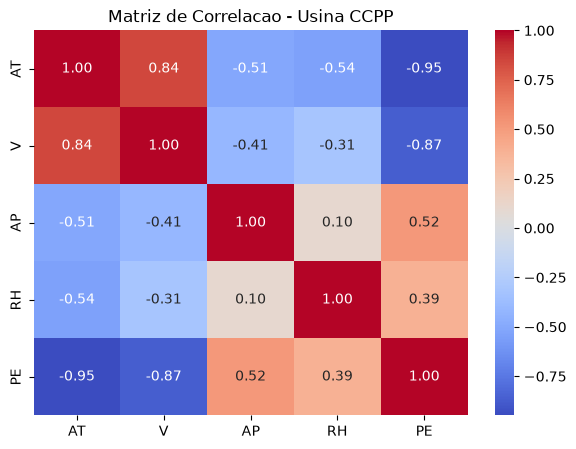

In [2]:
## Calculando a matriz de correlacao entre todas as variaveis
correlacao = df.corr() ## metodo do pandas para calcular a correlação entre colunas numéricas
print('Matriz de Correlacao:') ## Printando o cabeçalho da minha representação de dados

## Amostrar os dados após a correlação feita  - - - - - PRECISO REVISAR A QUESTÃO DA CORRELAÇÃO AQUI
print(correlacao.round(4)) ## trabalhando com 4 casas decimais aqui 
## Nesse caso, quando menor o valor do parâmetros, menos casas decimais de representação dos dados

## Plotando o mapa de calor para facilitar a visualizacao
plt.figure(figsize=(7, 5)) ## Aqui, eu estou configurando por exemplo, o tamanho da minha figura
## Basicamente eu estou reservando um quadro ed tamanho 7 por 5

## sns é a forma como acessamos o Seaborn
## aqui, estamos facilitando a nossa vida na representação dos dados juntos do matplotlib
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt='.2f') ## Dentro da figura plotada
## estou configurando o heatmap
## --> passo a correlação como primeiro argumento (pois estou fazendo o heatmap com base nela)
## --> annot = True, vai me entregar a questão da centralização da representação do dado em cada quadrado ....
## --> O cmap = coloração do mapa de cores, que é escolhido pelo parâmetro
## --> coolwarm = parâmetro que usamos junto com o cmap para a representação de negativo sendo azul e positivo sendo vermelho 
## --> fmt = é como eu estou configurando a questao de casas decimais na representação dos dados ..


plt.title('Matriz de Correlacao - Usina CCPP') ## só a questão de configuraçao do título da minha representação
## plt.tight_layout() ## ajustando o layout no matplotlib. basicamente um ajuste para que tenhamos um calculo automático do espaço necesário para organizar as margens de tudo (titulo, eixo e números)
plt.show() ## Aqui, eu estou basicamente plotando na tela. é o necessário para que enxerguemos o gráfico
## ambos os plts, são desnecessários no jupyter notebook, mas vamos deixar por questão de limpeza de tela

## LEMBRANDO, PARA AS ANÁLISES, SEMPRE FAZ SENTIDO ANALIZAR A PARTIR DE UMA REGIÃO ACIMA OU ABAIXO DA DIAGONAL PRINCIPAL NA MATRIZ DE CORRELAÇÃO 
## pq basicamente ele é espelhada para quando vamos tirar as conclusões

### Análise das Tarefas 1 e 2

**1. Correlação entre as variáveis independentes (AT, V, AP, RH) e a variável dependente (PE):**
- **AT (Temperatura Ambiente):** possui correlação de **-0.9481** com PE (correlação negativa muito forte).
- **V (Vácuo de Escape):** possui correlação de **-0.8698** com PE (correlação negativa forte).
- **AP (Pressão Atmosférica):** possui correlação de **0.5184** com PE (correlação positiva moderada).
- **RH (Umidade Relativa):** possui correlação de **0.3898** com PE (correlação positiva fraca a moderada).

Portanto, as variáveis que têm **maior influência** na produção de energia são **AT** e **V**. Quando a temperatura ambiente ou o vácuo de escape aumentam, a potência elétrica gerada pela usina diminui.

**2. Correlação das variáveis independentes entre si (Multicolinearidade):**
- Observa-se uma correlação positiva forte de **0.8441** entre **AT** e **V**.
- Também há correlações negativas moderadas entre **AT e RH (-0.5425)** e entre **AT e AP (-0.5075)**.
- A relação forte entre AT e V indica a presença de **multicolinearidade**, já que ambas carregam informações parcialmente redundantes para o modelo linear.

## Tarefa 3: Pré-processamento, Divisão Treino/Teste e Modelo de Regressão Linear Múltipla

In [3]:
## Separando as variaveis independentes (X) e a variavel dependente alvo (y)
## Passo 1 (Corte Vertical nas Colunas): antes de separar treino e teste, precisamos dizer ao Python quem são as entradas e quem é a saída
X = df[['AT', 'V', 'AP', 'RH']] ## estou basicamente separando essas 4 colunas do meu Data Frame (justamente pelo fato de serem as variáveis independentes / sensores) 
## print (f"{X.head()}") ## para caso queira validar a representação a partir das independentes
y = df['PE'] ## estou basicamente separando também essa coluna do meu DataFrame (essa é a nossa variável dependente / alvo que queremos prever)
## print (f"{y.head()}") ## para caso queira validar a separação por meio da dependente


## Dividindo os dados em treino (80%) e teste (20%)
## Passo 2 (Corte Horizontal nas Linhas): das 9568 linhas, 80% (7654 linhas) vão para o treino e 20% (1914 linhas) vão para o teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
## vale salientar que, a configuração do conjunto de treino é feito como pares e A ORDEM IMPORTA:
## --> 1º Par (X_train, X_test) -> recebe os 80% de treino e os 20% de teste do primeiro argumento da função (X)
## --> 2º Par (y_train, y_test) -> recebe os 80% de treino e os 20% de teste do segundo argumento da função (y)
## --> "test_size = 0.2": Estou configurando o tamanho do conjunto de testes para ser 20% (0.2) de todas as tuplas.
##     Concorda que, se eu configuro o test_size = 0.2, automaticamente eu já estou dizendo que o meu conjunto de treino é o resto (80%)?
## --> "random_state = 42": Antes de cortar 80/20, a função embaralha as linhas como um baralho.
##     O número 42 trava a semente desse sorteio para que, toda vez que eu rodar o notebook, caia exatamente a mesma divisão e o mesmo resultado final.


## Padronizando as variaveis independentes (Z-score: media 0 e desvio padrao 1)
## Por que padronizar aqui? Porque as unidades são muito distantes (AT fica na casa de 20 °C, enquanto AP passa de 1000 mbar).
## Colocando todas na mesma escala (Z-score), conseguimos comparar justamente os pesos (coeficientes) de cada variável depois.
scaler = StandardScaler() ## instanciando a ferramenta de padronização do scikit-learn
X_train_scaled = scaler.fit_transform(X_train) ## no TREINO usamos fit_transform:
## --> .fit(): calcula a média e o desvio padrão usando APENAS os 80% de treino
## --> .transform(): aplica a conta (valor - media) / desvio para padronizar os dados de treino
X_test_scaled = scaler.transform(X_test) ## no TESTE usamos SÓ .transform() (SEM o fit!):
## --> aplicamos no teste a mesma média e desvio aprendidos no treino.
## --> fazemos isso para evitar vazamento de dados (data leakage), ou seja, para o modelo não ter nenhuma informação adiantada do conjunto de teste.


## Criando e treinando o modelo de Regressao Linear Multipla
## Fórmula matemática que o modelo vai montar: PE = b0 + (w1 * AT) + (w2 * V) + (w3 * AP) + (w4 * RH)
modelo = LinearRegression() ## Acesso a metodologia do modelo para trabalhar (instanciando o modelo ainda vazio)
modelo.fit(X_train_scaled, y_train) ## .fit() é onde acontece o treinamento: entregamos os sensores padronizados de treino e o gabarito (y_train) para ele achar os pesos

print('Intercepto (b0):', round(modelo.intercept_, 4)) ## modelo.intercept_ é o b0 da equação (produção média esperada de 454.43 MW quando os sensores estão na média 0)
for nome, coef in zip(X.columns, modelo.coef_): ## zip() junta o nome de cada coluna (AT, V, AP, RH) com o peso que o modelo calculou em modelo.coef_
    print(f'Coeficiente {nome}: {coef:.4f}') ## imprimindo com 4 casas decimais: veja que AT tem o maior peso (-14.7639), batendo com a correlação da Tarefa 1

Intercepto (b0): 454.431
Coeficiente AT: -14.7639
Coeficiente V: -2.9496
Coeficiente AP: 0.3698
Coeficiente RH: -2.3122


## Tarefa 4: Avaliação do Desempenho do Modelo

R2 (Coeficiente de Determinacao): 0.9301
RMSE (Raiz do Erro Quadratico Medio): 4.5026 MW
MAE (Erro Medio Absoluto): 3.5959 MW


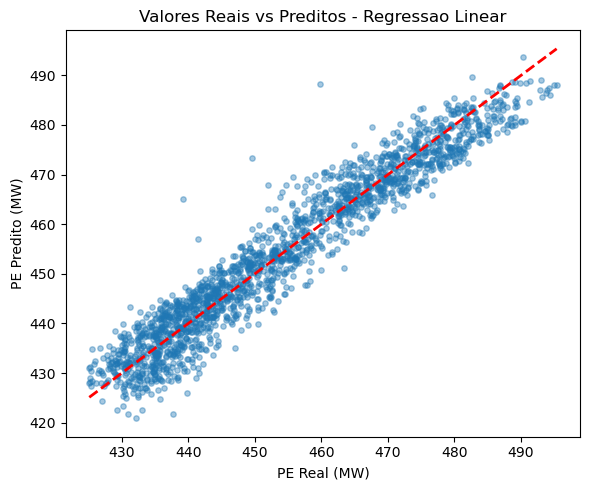

In [4]:
## Fazendo as previsoes no conjunto de teste (Prova Final do Modelo)
## Agora que o modelo já foi treinado com os 80%, entregamos os 20% dos sensores de teste (X_test_scaled) para ele prever a energia
y_pred = modelo.predict(X_test_scaled) ## y_pred guarda os 1914 chutes de produção de energia feitos pelo modelo

## Calculando as metricas R2, RMSE e MAE (comparando o gabarito real 'y_test' com a previsão 'y_pred')
r2 = r2_score(y_test, y_pred)
## --> R2 (Coeficiente de Determinação): varia de 0 a 1. Deu 0.9301, ou seja, 93,01% da variação da energia da usina é explicada pelo nosso modelo.
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
## --> mean_squared_error calcula a média dos erros ao quadrado (MSE), e o np.sqrt tira a raiz quadrada para voltar para a unidade de Megawatts (RMSE = 4.5026 MW).
## --> Como eleva os erros ao quadrado antes de tirar a média, o RMSE pune mais fortemente caso o modelo cometa algum erro grande isolado.
mae = mean_absolute_error(y_test, y_pred)
## --> MAE (Erro Médio Absoluto): é a média simples da diferença |real - previsto|. Deu 3.5959 MW (em média o modelo erra só 3,6 MW para mais ou para menos).

print(f'R2 (Coeficiente de Determinacao): {r2:.4f}') ## exibindo o R2 com 4 casas decimais
print(f'RMSE (Raiz do Erro Quadratico Medio): {rmse:.4f} MW') ## exibindo o RMSE em MW
print(f'MAE (Erro Medio Absoluto): {mae:.4f} MW') ## exibindo o MAE em MW

## Grafico comparando valores reais vs valores preditos
plt.figure(figsize=(6, 5)) ## reservando um quadro de tamanho 6 por 5 para desenhar o gráfico
plt.scatter(y_test, y_pred, alpha=0.4, s=15) ## scatter desenha o gráfico de dispersão (nuvem de pontos):
## --> eixo X recebe o valor real (y_test) e eixo Y recebe o valor previsto (y_pred)
## --> alpha=0.4 deixa as bolinhas levemente transparentes para vermos onde os pontos se concentram mais
## --> s=15 define o tamanho visual de cada bolinha
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
## --> desenha uma reta diagonal vermelha tracejada ('r--') de espessura 2 (lw=2) que vai do menor ao maior valor de energia.
## --> Essa linha vermelha representa o acerto perfeito (onde Previsto = Real). Quanto mais colados na linha vermelha estão os pontos azuis, melhor é o modelo!
plt.xlabel('PE Real (MW)') ## nomeando o eixo X
plt.ylabel('PE Predito (MW)') ## nomeando o eixo Y
plt.title('Valores Reais vs Preditos - Regressao Linear') ## título do gráfico
plt.tight_layout() ## organizando as margens automaticamente
plt.show() ## plotando na tela

## LEMBRANDO PARA A APRESENTAÇÃO (Tarefa 4):
## Por que o modelo é adequado? Porque explica 93% dos dados (R2 = 0.93) e erra em média só 3.6 MW (MAE) numa usina que gera ~454 MW (erro menor que 1%).

### Análise da Tarefa 4

**Métricas obtidas no conjunto de teste:**
- **$R^2$:** `0.9301`
- **RMSE:** `4.5026 MW`
- **MAE:** `3.5959 MW`

**O modelo é adequado para prever a produção de energia? Justificativa:**
Sim, o modelo é adequado. O coeficiente de determinação ($R^2 = 0.9301$) mostra que aproximadamente **93% da variação** na potência elétrica gerada pela usina é explicada linearmente pelas quatro variáveis ambientais. Além disso, considerando que a produção de energia varia entre cerca de 420 MW e 495 MW, um erro médio absoluto (MAE) de **3.60 MW** e um RMSE de **4.50 MW** representam um erro percentual abaixo de 1%, indicando boa precisão para auxiliar na estimativa de despacho energético.